In [8]:
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt

In [9]:
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

In [10]:
df=pd.read_csv("customer_master.csv")
df

,customer_id,customer_name,customer_age,gender,customer_segment,customer_city,customer_state,customer_country,region,customer_postal_code,customer_acquisition_cost
0,CUST-000001,Donna Miller,54,Female,Consumer,Laurenland,Dubai,UAE,South,11253,13.58
1,CUST-000002,Joseph James,61,Male,Consumer,Lake Peter,Lower Saxony,Germany,North,47778,27.45
2,CUST-000003,Daniel Smith,47,Male,Consumer,Seanview,North Rhine,Germany,West,13900,31.53
3,CUST-000004,David Lopez,30,Male,VIP,Hawkinshaven,Pennsylvania,USA,East,53984,16.02
4,CUST-000005,Dakota Davis,55,Female,Consumer,New Carlymouth,Florida,USA,South,50994,41.34
...,...,...,...,...,...,...,...,...,...,...,...
24995,CUST-024996,Nathan Porter,40,Male,Consumer,Kristineport,Texas,USA,South,62079,14.92
24996,CUST-024997,Heather Graham,19,Female,Consumer,Ruizside,North Rhine,Germany,West,16488,11.41
24997,CUST-024998,John Smith,31,Female,Business,Jacksonside,North Carolina,USA,South,86726,66.95
24998,CUST-024999,Eric Castillo,52,Female,Consumer,West Brandonfort,Ontario,Canada,East,92053,24.97


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                25000 non-null  str    
 1   customer_name              25000 non-null  str    
 2   customer_age               25000 non-null  int64  
 3   gender                     25000 non-null  str    
 4   customer_segment           25000 non-null  str    
 5   customer_city              25000 non-null  str    
 6   customer_state             25000 non-null  str    
 7   customer_country           25000 non-null  str    
 8   region                     25000 non-null  str    
 9   customer_postal_code       25000 non-null  int64  
 10  customer_acquisition_cost  25000 non-null  float64
dtypes: float64(1), int64(2), str(8)
memory usage: 3.7 MB


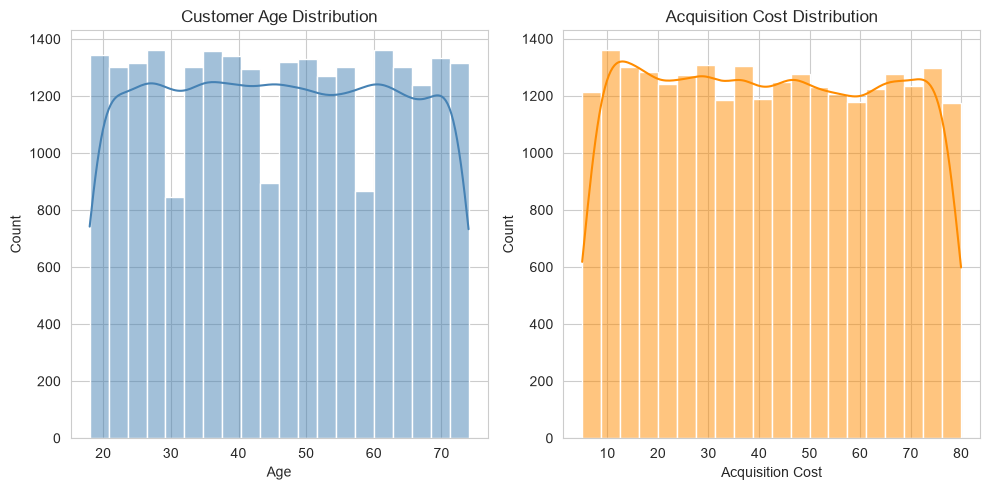

In [12]:
fig, axes = plt.subplots(1, 2)

sns.histplot(
    df["customer_age"], bins=20, kde=True, ax=axes[0], color="steelblue"
)
axes[0].set_title("Customer Age Distribution")
axes[0].set_xlabel("Age")

sns.histplot(
    df["customer_acquisition_cost"],
    bins=20,
    kde=True,
    ax=axes[1],
    color="darkorange",
)
axes[1].set_title("Acquisition Cost Distribution")
axes[1].set_xlabel("Acquisition Cost")

plt.tight_layout()
plt.show()

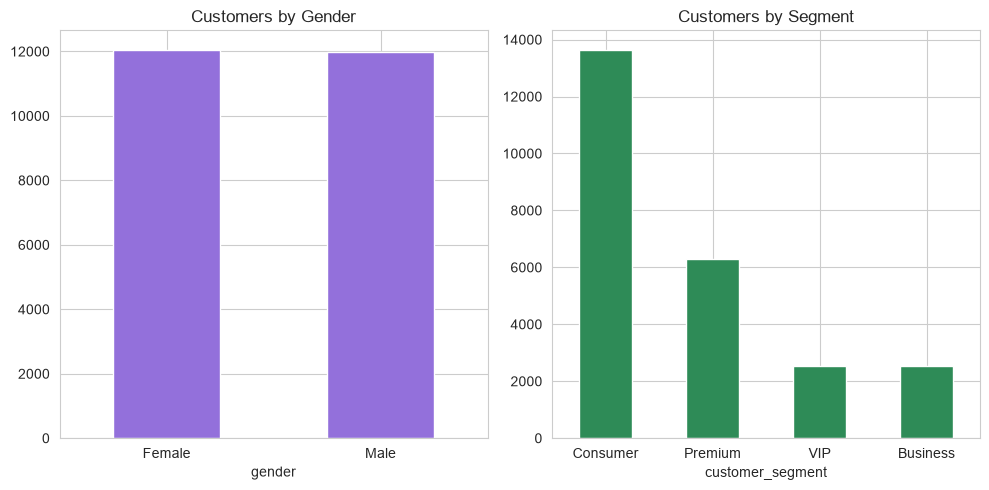

In [14]:
fig, axes = plt.subplots(1, 2)

gender_counts = df[
    ~df["gender"].astype(str).str.strip().str.lower().isin(["non-binary", "non binary"])
]["gender"].value_counts()

gender_counts.plot(kind="bar", ax=axes[0], color="mediumpurple")
axes[0].set_title("Customers by Gender")
axes[0].tick_params(axis="x", rotation=0)

df["customer_segment"].value_counts().plot(
    kind="bar", ax=axes[1], color="seagreen"
)
axes[1].set_title("Customers by Segment")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

In [15]:
unique_ids = df["customer_id"].is_unique
duplicate_rows = df.duplicated().sum()
duplicate_names = df["customer_name"].duplicated().sum()

pd.Series({
    "customer id is unique": unique_ids,
    "duplicate rows": duplicate_rows,
    "duplicate names": duplicate_names,
})

customer id is unique    True
duplicate rows              0
duplicate names          3369
dtype: object

In [16]:
country_summary = (
    df.groupby("customer_country")
    .agg(
        customer_count=("customer_id", "count"),
        avg_age=("customer_age", "mean"),
        avg_acquisition_cost=("customer_acquisition_cost", "mean"),
    )
    .sort_values("customer_count", ascending=False)
)

In [18]:
country_summary

,customer_count,avg_age,avg_acquisition_cost
customer_country,,,
USA,14925,45.928777,42.085881
UK,3701,45.883545,42.274712
Germany,2046,45.640762,42.217571
Canada,1279,46.275215,42.612651
Australia,1233,45.689376,42.972758
India,1041,46.024976,41.831585
UAE,775,45.909677,41.280594


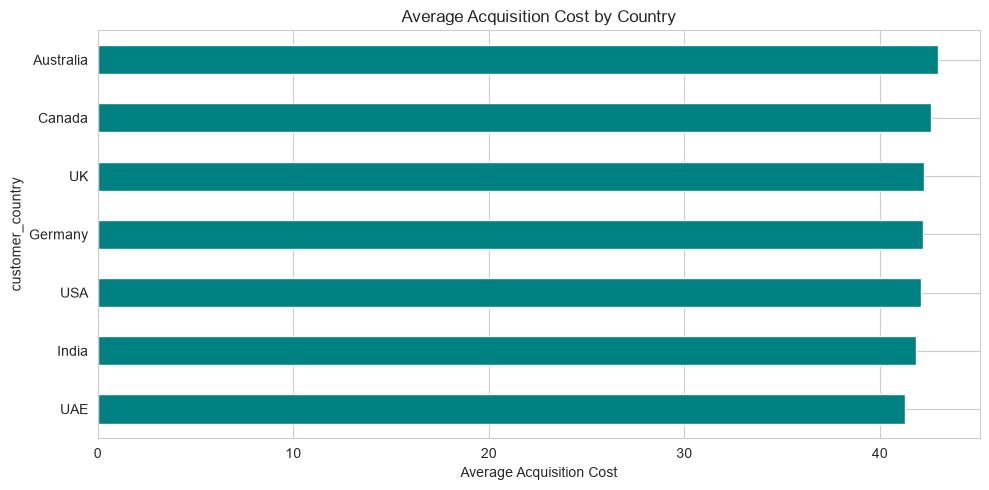

In [19]:
country_summary["avg_acquisition_cost"].sort_values().plot(
    kind="barh", color="teal"
)
plt.title("Average Acquisition Cost by Country")
plt.xlabel("Average Acquisition Cost")
plt.tight_layout()
plt.show()

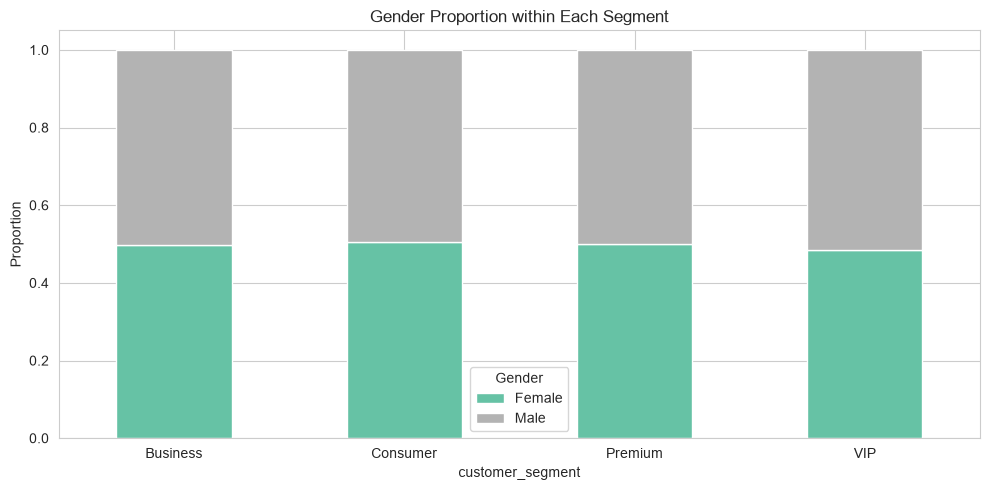

In [21]:
# استبعاد Non-binary من عمود الجنس
filtered_df = df[
    ~df["gender"]
    .astype(str)
    .str.strip()
    .str.lower()
    .isin(["non-binary", "non binary"])
]

segment_gender = pd.crosstab(
    filtered_df["customer_segment"], filtered_df["gender"], normalize="index"
)
segment_gender.plot(kind="bar", stacked=True, colormap="Set2")
plt.title("Gender Proportion within Each Segment")
plt.ylabel("Proportion")
plt.xticks(rotation=0)
plt.legend(title="Gender")
plt.tight_layout()
plt.show()

In [22]:
pivot = df.pivot_table(
    values="customer_acquisition_cost",
    index="region",
    columns="customer_segment",
    aggfunc="mean",
)

In [24]:
pivot

customer_segment,Business,Consumer,Premium,VIP
region,,,,
Central,42.665208,42.381241,42.033338,40.903996
East,41.582421,41.498164,42.068956,43.113654
North,43.024669,42.521355,42.938065,39.870359
South,42.419132,42.260161,41.927955,42.680490
West,42.257776,42.587711,41.129324,42.167195


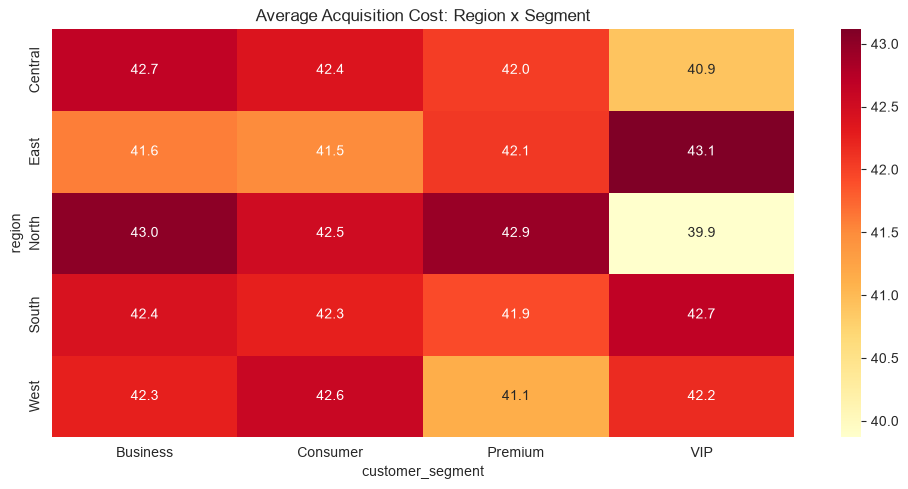

In [25]:
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="YlOrRd")
plt.title("Average Acquisition Cost: Region x Segment")
plt.tight_layout()
plt.show()

In [26]:
df["postal_len"] = df["customer_postal_code"].astype(str).str.len()
postal_by_country = pd.crosstab(df["customer_country"], df["postal_len"])
postal_by_country

postal_len,3,4,5
customer_country,,,
Australia,6,106,1121
Canada,7,124,1148
Germany,7,183,1856
India,2,91,948
UAE,3,56,716
UK,19,324,3358
USA,80,1368,13477


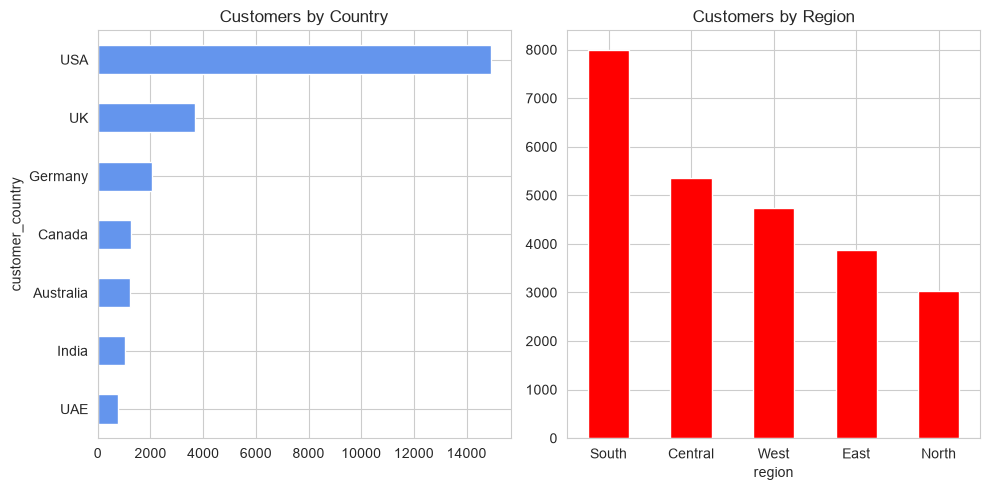

In [27]:
fig, axes = plt.subplots(1, 2)

df["customer_country"].value_counts().plot(
    kind="barh", ax=axes[0], color="cornflowerblue"
)
axes[0].set_title("Customers by Country")
axes[0].invert_yaxis()

df["region"].value_counts().plot(kind="bar", ax=axes[1], color="red")
axes[1].set_title("Customers by Region")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

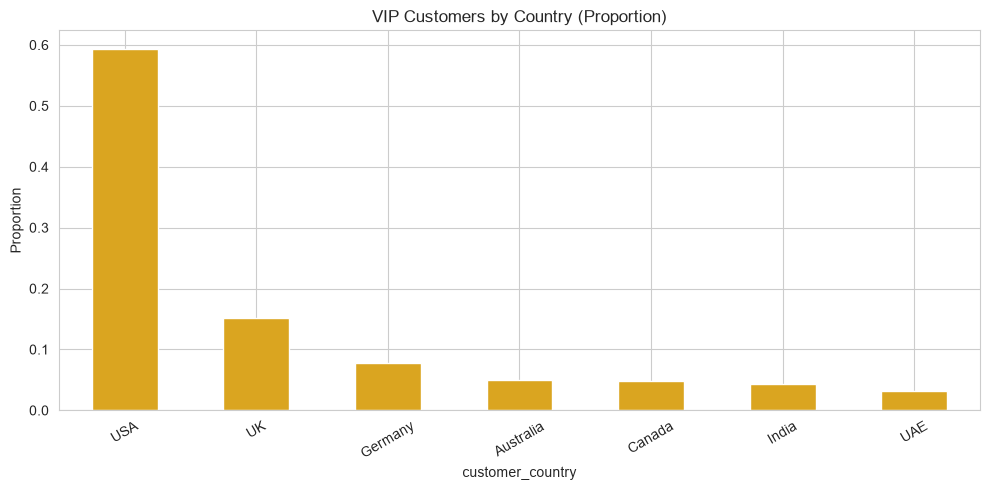

In [28]:
vip_by_country = df[df["customer_segment"] == "VIP"][
    "customer_country"
].value_counts(normalize=True)

vip_by_country.plot(kind="bar", color="goldenrod")
plt.title("VIP Customers by Country (Proportion)")
plt.ylabel("Proportion")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()